# 12-T800的观测空间


## 1. 本课目标：1083 维观测是怎样组成的

本篇对应《具身智能机器人实战》第 12 节《T800 的观测空间》，副标题为“observation space 1083 怎么来的”。上一节介绍策略根据状态生成动作，本节继续回答：策略到底接收哪些信息，为什么输入会有 1083 维？

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/12_T800的观测空间.pptx` 全部 7 页：第 2 页对比人与机器人的感知，第 3 页拆解单帧数据，第 4、5 页引入运动趋势和历史帧，第 6 页加入用户命令，第 7 页为品牌结束页。

课件给出了观测项与维度推导，没有展示观测构造代码、22 个关节的名称与顺序、数据缩放或模型张量布局。下面先按课件说明组成，必要的接口解释标为“工程补充”。未转录配套视频 `12_t800的观测空间.mp4`，也未读取网盘中的 `code.zip`。


## 2. 机器人怎样知道自己正在怎样运动

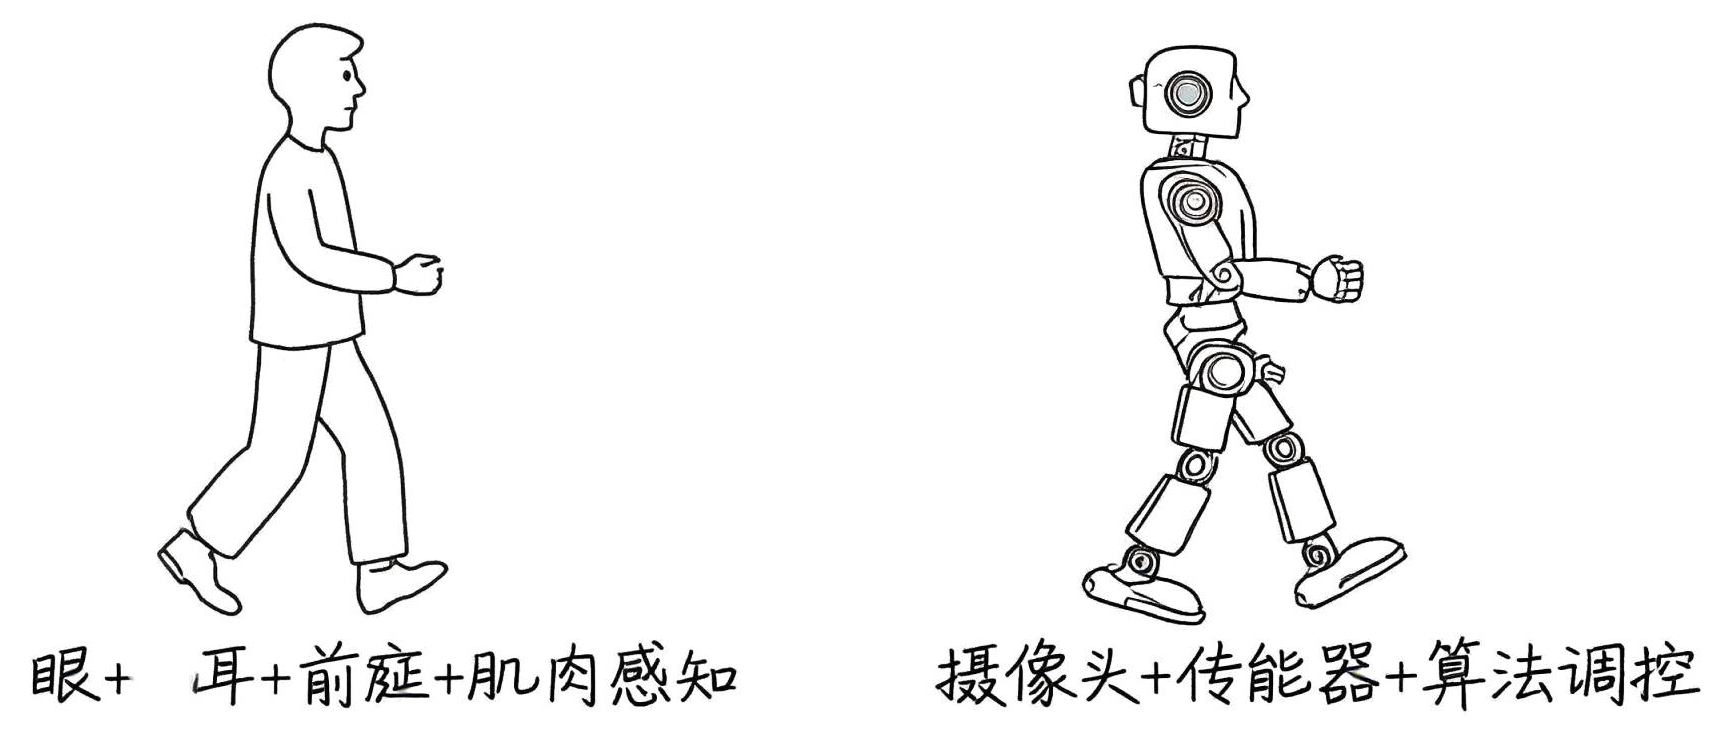

*原课件第 2 页：人通过“眼 + 耳 + 前庭 + 肌肉感知”，机器人通过“摄像头 + 传感器 + 算法调控”完成感知与运动配合。*

人走路时，不是只看脚的位置。视觉、听觉、前庭提供的平衡信息，以及肌肉和关节的身体感觉，一起帮助判断姿态和运动情况。机器人也需要来自自身和环境的信息，再由算法据此决定动作。

在策略控制中，**观测（observation）**就是按策略接口整理后提供给网络的信息；观测空间描述这些输入的组成、维度及允许取值等约定。本课重点是解释输入维度。

**工程补充：**图中的摄像头是机器人感知的一般例子。后面的 1083 维方案由身体状态历史和用户命令组成，课件没有把图像像素列入其中，不能把“机器人可以用摄像头”理解为这份策略一定接收摄像头画面。


## 3. 单帧身体观测：22 + 22 + 22 + 3 + 3 = 72

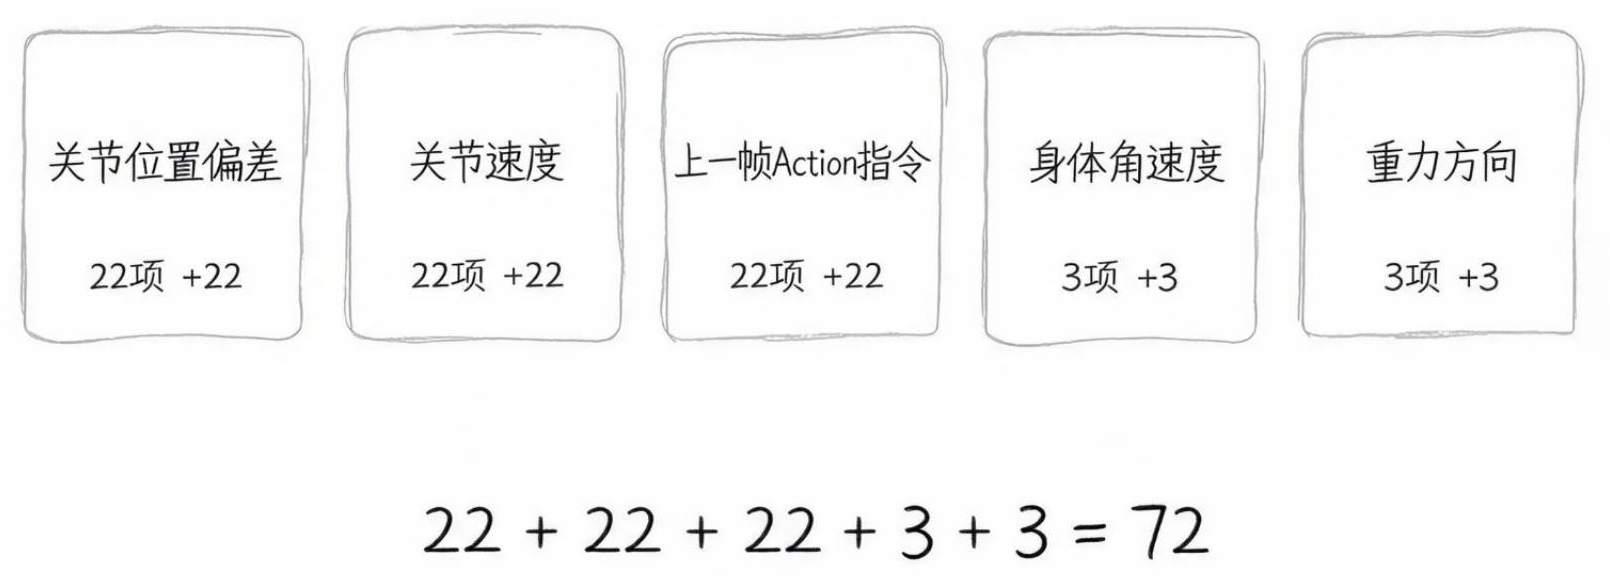

*原课件第 3 页：关节位置偏差、关节速度、上一帧 Action 指令各 22 项，身体角速度与重力方向各 3 项。*

| 观测项 | 维度 | 提供的信息 |
|---|---:|---|
| 关节位置偏差 | 22 | 当前关节位置相对参考位置的偏离情况 |
| 关节速度 | 22 | 关节正在怎样转动 |
| 上一帧 Action 指令 | 22 | 策略上一次给出的动作信息 |
| 身体角速度 | 3 | 身体绕三个方向转动的快慢与方向 |
| 重力方向 | 3 | 用于感知身体朝向与倾斜的方向信息 |

把五类信息放在同一帧里，得到：

$$
d_{\mathrm{frame}}=22+22+22+3+3=72
$$

这里一“维”对应输入向量中的一个数值分量。72 维是整理后的单帧身体信息长度，不是 72 个关节，也不是 72 个独立传感器。

位置和速度说明“现在是什么状态”，上一帧动作补充“之前下过什么指令”，身体角速度与重力方向则帮助策略了解身体运动和倾斜情况。

**工程补充：**本课用 22 组关节相关数据，不等于前几篇核对的官方仿真模型中全部 25 个 motor 都进入了策略。具体选择哪 22 个、按什么顺序排列，需要查课程策略配置，不能直接截取 `qpos` 或 `qvel` 的前 22 项。

“关节位置偏差”也不能直接套用第 08 篇 PD 的目标误差公式：参考姿态是什么、差值取哪个方向、是否缩放，要与策略训练时的约定一致。上一帧 Action 同样不能未经核对就用上一帧 `ctrl` 代替；策略动作经过转换后才可能成为执行器输入。重力方向通常会在身体坐标系下表达以反映倾斜，课件未指定坐标系、归一化和变换实现。


## 4. 为什么还要保留历史：15 × 72 = 1080

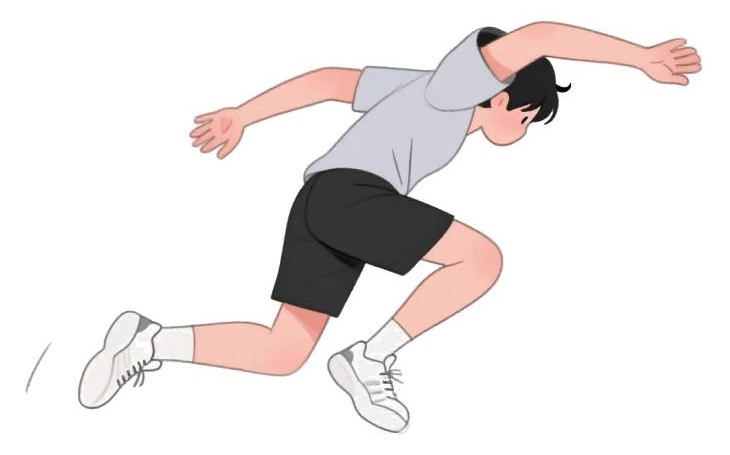

*原课件第 4 页用身体失衡的姿态引出运动趋势问题，该页没有额外文字说明。*

看到某一刻身体倾斜，还需要判断它是在继续倒下，还是正在恢复平衡。课件接着把单帧数据与连续历史帧作对比：

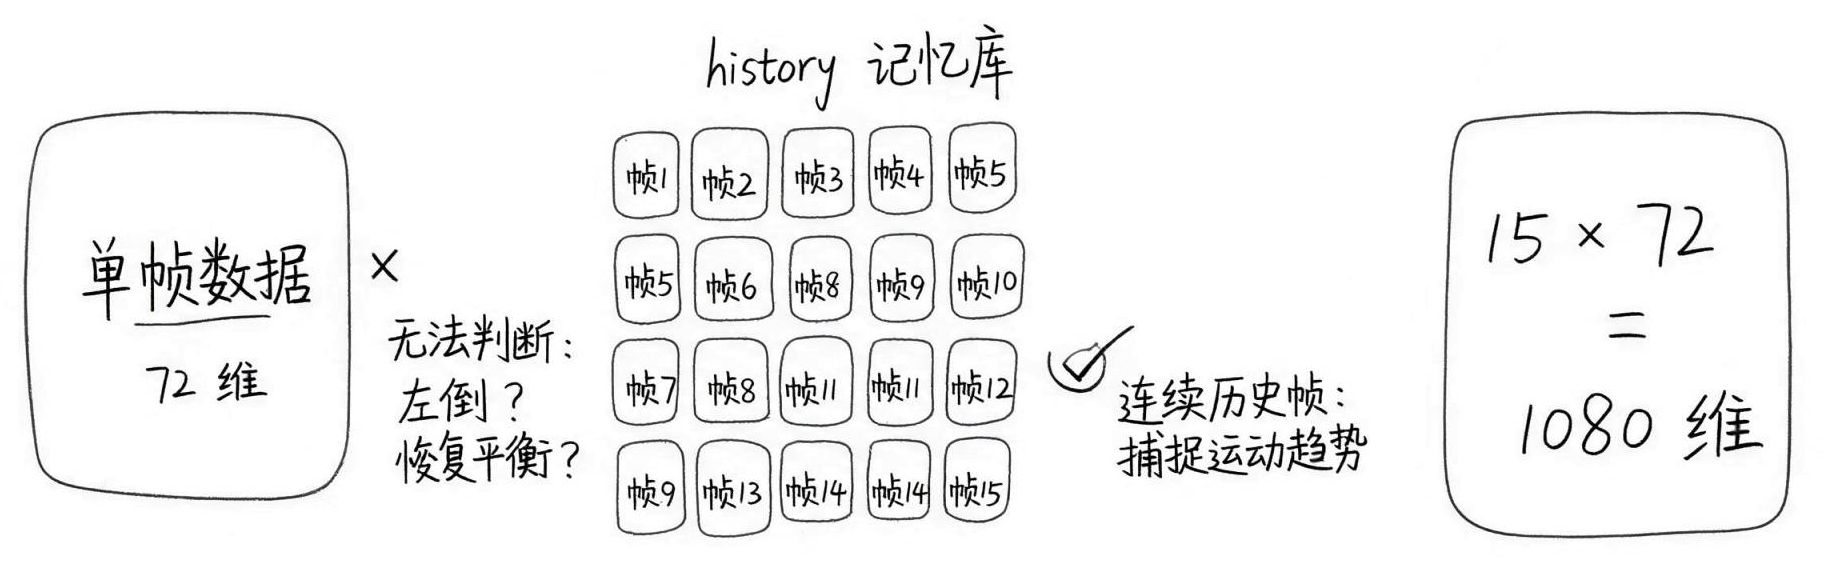

*原课件第 5 页：单帧 72 维，连续历史帧用来捕捉运动趋势；15 帧合计 1080 维。*

历史缓存（history）保存连续多帧身体观测。策略同时看到这段时间内的信息变化，就能利用运动趋势作出判断，而不只依赖一个瞬间。

本课使用 15 帧，每帧 72 维：

$$
d_{\mathrm{history}}=15\times72=1080
$$

可以把它理解成把 15 份身体观测按约定顺序拼在一起。**这 15 帧合计为 1080 维**，不是在 1080 维之外再额外加一份当前帧。

**工程补充：**单帧中已经包含速度，能提供部分运动趋势信息；课件的“无法判断”用于强调历史的作用，不表示任何单帧观测都完全无法判断运动。图中的小卡片有重复和不连续的帧号，用作示意即可，维度按课件明确写出的 `15 × 72` 计算。

实现时还需约定历史按新到旧还是旧到新排列、初始化不足 15 帧时怎样填充，以及多久采样一次。这里的“帧”指观测采样，不必等于画面刷新或一次 `mj_step()`。课件未给出采样间隔，因此不能仅凭 15 帧推算覆盖了多少秒。


## 5. 加入用户命令：1080 + 3 = 1083

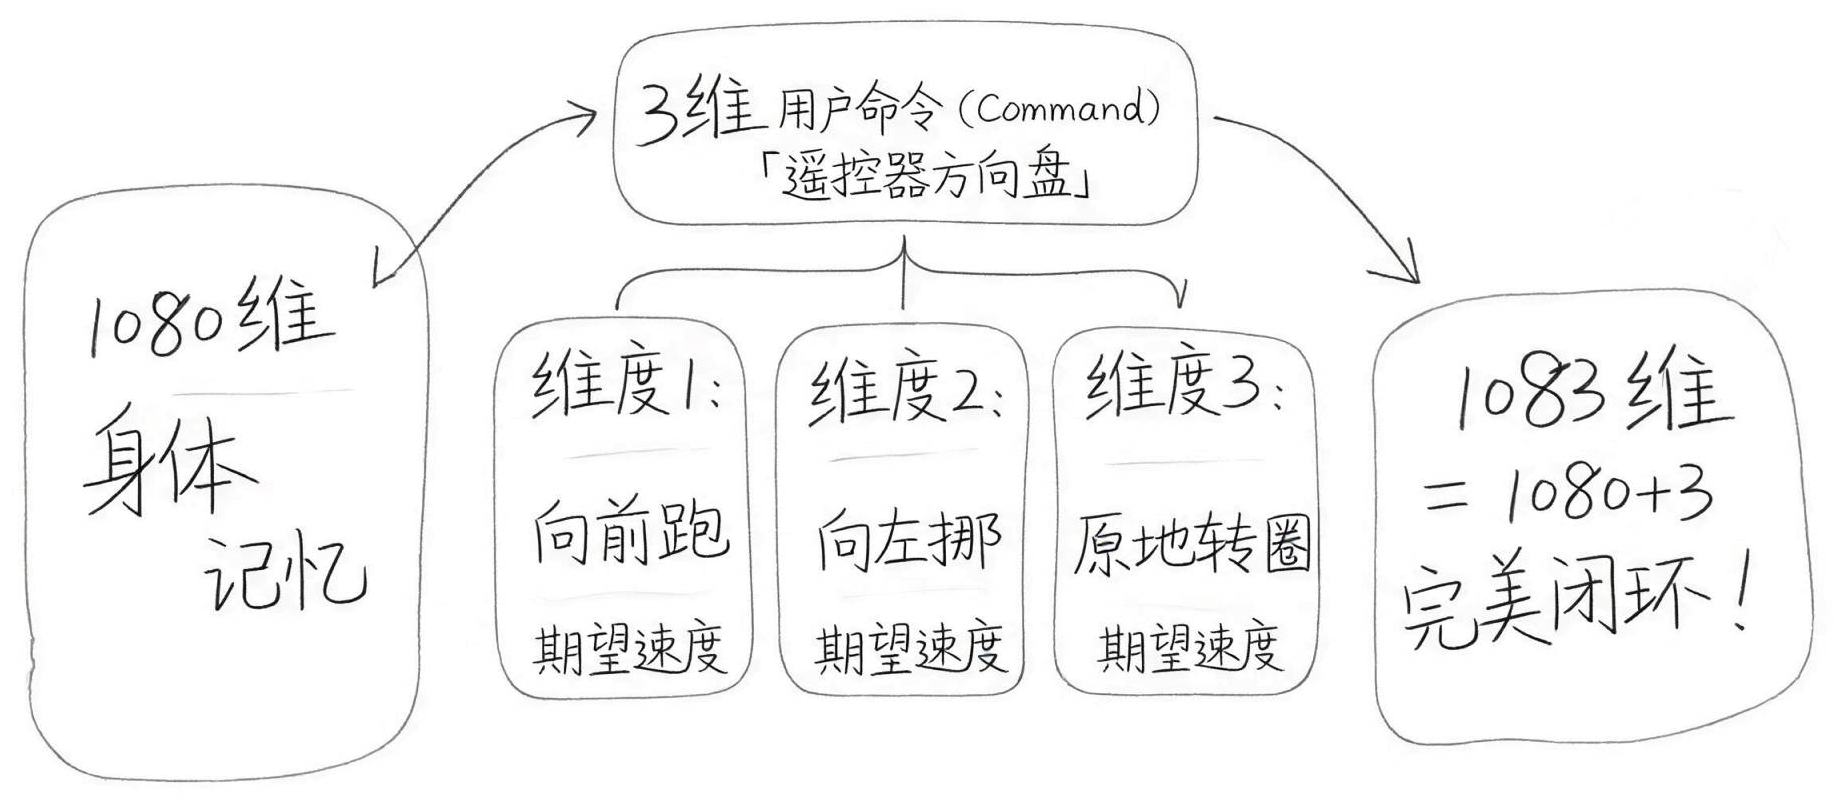

*原课件第 6 页：1080 维身体记忆，加上“遥控器方向盘”式的 3 维 Command，组成 1083 维输入。*

身体状态说明“机器人现在怎样”，用户命令（Command）说明“希望机器人怎样运动”。课件把这部分比作遥控器方向盘，分为三个维度：

| 命令维度 | 课件中的动作描述 | 对应意图 |
|---|---|---|
| 维度 1 | 向前跑，期望速度 | 希望前后移动多快 |
| 维度 2 | 向左挪，期望速度 | 希望左右移动多快 |
| 维度 3 | 原地转圈，期望速度 | 希望转向多快 |

身体历史与当前命令合起来：

$$
\begin{aligned}
d_{\mathrm{obs}}
&=d_{\mathrm{history}}+d_{\mathrm{command}}\\
&=15\times(22+22+22+3+3)+3\\
&=1080+3=1083
\end{aligned}
$$

这里的 3 维命令在历史身体信息之外加入一次。按本课结构，不是把每帧都扩成 75 维再乘以 15；后者会得到 1125，已经改变输入方案。

**工程补充：**前两项通常是平移速度目标，转向项通常是角速度目标，物理单位并不相同。它们是用户期望值，不是传感器测到的实际速度。具体坐标轴、正负方向、数值范围和缩放由策略接口规定，课件只解释这三个维度的运动含义。

图中把 1083 维输入称为“完美闭环”，可以理解为策略同时得到身体反馈和用户意图。真正形成控制闭环，还需要继续执行“策略输出动作 → 执行器驱动 → 身体状态变化 → 读取新观测”；输入长度正确本身不保证机器人运动稳定。


## 6. 本课检查

本节的推导顺序是：先整理 72 维单帧身体信息，再堆叠 15 帧得到 1080 维身体历史，最后加 3 维用户命令，得到 1083 维策略观测。

完成本节，应能分别解释五类身体信息为什么需要、历史帧怎样帮助捕捉运动趋势，以及用户命令和实际状态的区别。接入模型时，除了核对总长度，还要核对关节选择、分量顺序、参考姿态、单位、缩放与历史排列。

本篇已逐页核对课件并校验维度运算。课件未提供实际观测拼接代码和 MNN 张量接口，本篇没有推定完整张量形状，也没有加载策略模型、执行推理或验证 T800 行走。
